# 02 · Hipóteses de jogo — o que realmente pesa aos 10 minutos?

A EDA mostrou **associações brutas**: quem pega dragão vence 64%, quem faz first blood vence
60%. Mas quem está na frente em gold também pega mais dragão e mais first blood. Este
notebook separa **"o objetivo ajuda"** de **"quem já está ganhando pega o objetivo"**.

Cada hipótese segue o mesmo roteiro: **H0/H1 → teste → tamanho de efeito → IC → conclusão
em linguagem de jogador.**

**Sobre os dados:** uso as 9.879 partidas (camada bronze). Aqui é **inferência**, não seleção
de modelo: nenhum número deste notebook vira parâmetro do modelo, e a escolha de features será
feita só por validação cruzada no treino (Etapa 5). Com isso o holdout de teste continua
limpo, e as estimativas ganham o N completo.

**Sobre causalidade:** o dataset é um snapshot sem ordem temporal. Os resultados são
**associações controladas pelo gold**, não efeitos causais.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

from lol_win.analysis.eda import TEAM_PALETTE, save_figure, set_plot_style
from lol_win.analysis.hypotheses import (
    bootstrap_gold_equivalent,
    chi2_association,
    fit_logit,
    minimum_detectable_effect,
    odds_ratio_table,
    proportion_test,
    raw_vs_adjusted_odds,
)
from lol_win.config import BRONZE_PARQUET, TARGET
from lol_win.data.schemas import BRONZE_SCHEMA
from lol_win.features.build import clip_upper, side_diffs

set_plot_style()
pd.set_option("display.float_format", "{:,.4f}".format)

N_BOOT = 1000
WARDS_CAP_QUANTILE = 0.99
GOLD = "total_gold_diff"
PER = {GOLD: 1000, "wards_placed_diff": 10, "wards_destroyed_diff": 10}

In [2]:
df = BRONZE_SCHEMA.validate(pd.read_parquet(BRONZE_PARQUET), lazy=True)
all_wards = pd.concat([df["blue_wards_placed"], df["red_wards_placed"]])
wards_cap = all_wards.quantile(WARDS_CAP_QUANTILE)
games = side_diffs(df).assign(
    wards_placed_diff=clip_upper(df["blue_wards_placed"], wards_cap)
    - clip_upper(df["red_wards_placed"], wards_cap),
    blue_first_blood=df["blue_first_blood"],
    **{TARGET: df[TARGET]},
)
print(f"{len(games):,} partidas · cap de wards_placed (p99) = {wards_cap:.0f}")

9,879 partidas · cap de wards_placed (p99) = 105


> **Unidades de leitura dos odds ratios:** gold por **+1.000**, wards por **+10**, objetivos
> e first blood por **+1**. Um odds ratio (OR) de 1,5 significa que as chances (odds) de
> vitória do azul ficam 50% maiores.

---
## H1 · O lado azul tem vantagem?

- **H0:** P(azul vence) = 0,5 · **H1:** P(azul vence) ≠ 0,5
- **Teste:** binomial exato bicaudal · **Efeito:** h de Cohen · **IC:** Clopper-Pearson (exato)

In [3]:
side = proportion_test(games[TARGET])
mde = minimum_detectable_effect(side.n)
pd.Series(
    {
        "partidas": side.n,
        "vitórias azuis": side.successes,
        "taxa azul": side.rate,
        "IC 95%": f"[{side.ci_low:.3f}, {side.ci_high:.3f}]",
        "p-valor": side.p_value,
        "h de Cohen": side.cohens_h,
        "menor efeito detectável (poder 80%)": f"±{mde:.3f}",
    },
    name="H1",
).to_frame()

,H1
partidas,9879
vitórias azuis,4930
taxa azul,0.4990
IC 95%,"[0.489, 0.509]"
p-valor,0.8563
h de Cohen,-0.0019
menor efeito detectável (poder 80%),±0.014


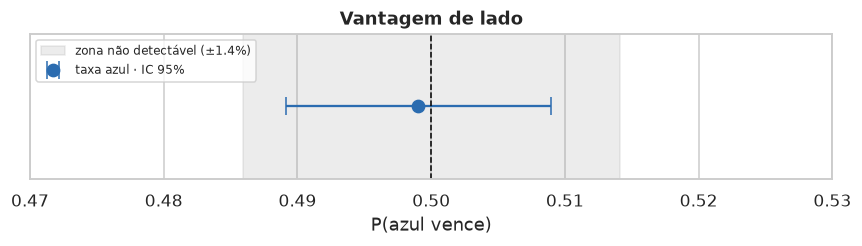

In [4]:
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.axvspan(
    0.5 - mde, 0.5 + mde, color="grey", alpha=0.15, label=f"zona não detectável (±{mde:.1%})"
)
ax.errorbar(
    side.rate,
    0,
    xerr=[[side.rate - side.ci_low], [side.ci_high - side.rate]],
    fmt="o",
    color=TEAM_PALETTE["blue"],
    capsize=6,
    markersize=8,
    label="taxa azul · IC 95%",
)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlim=(0.47, 0.53), yticks=[], xlabel="P(azul vence)", title="Vantagem de lado")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
save_figure(fig, "hyp_side_advantage")
plt.show()

**Conclusão:** não rejeitamos H0 (p ≈ 0,86). O IC 95% vai de 48,9% a 50,9% e o tamanho de
efeito é praticamente zero.

**Cuidado com a leitura:** "não detectado" é diferente de "não existe". Com 9.879 partidas,
o teste só enxergaria uma vantagem a partir de **~1,4 ponto percentual**. Vantagens de lado
relatadas em ranked costumam ficar em torno de 1–2 p.p., então uma vantagem pequena cabe no IC.

🎮 **Em linguagem de jogador:** nesta amostra de elo alto, jogar de azul ou de vermelho não muda
nada que dê para medir. Para o modelo, isso significa que **o lado sozinho não carrega
informação**: tudo está no que acontece nos 10 minutos.

---
## H2 · Quanto vale um dragão, um arauto e uma torre — em gold?

**Ideia:** num logit `blue_wins ~ gold_diff + objetivo_diff`, os dois coeficientes estão na
mesma escala (log-odds). A razão **β_objetivo / β_gold** responde: *quantos de gold de
vantagem mexem na chance de vitória o mesmo que +1 objetivo?* É uma "taxa de câmbio"
objetivo → gold.

- **H0:** β_objetivo = 0 (dado o gold, o objetivo não se associa à vitória) · **H1:** β_objetivo ≠ 0
- **Teste:** Wald no logit · **Efeito:** valor em gold · **IC:** bootstrap percentil (B = 1.000)

⚠️ **Ressalva central:** o `gold_diff` **já inclui** o gold que o objetivo rendeu (gold da
torre e dos plates, o gold do arauto usado em lane). O valor estimado é o efeito **além** desse
gold: visão de mapa, buff, pressão, o que o objetivo sinaliza sobre o estado da partida.

Modelo principal: **um objetivo por vez**, com gold como controle único (decisão 4 da EDA).
Os três juntos entram como verificação de robustez.

In [5]:
objectives = ["dragons_diff", "heralds_diff", "towers_destroyed_diff"]

separate = pd.concat(
    [bootstrap_gold_equivalent(games, [obj], GOLD, n_boot=N_BOOT) for obj in objectives]
)
joint = bootstrap_gold_equivalent(games, objectives, GOLD, n_boot=N_BOOT)
wald = pd.concat(
    [odds_ratio_table(fit_logit(games, [GOLD, obj]), per=PER).loc[[obj]] for obj in objectives]
)
gold_values = separate.join(wald[["odds_ratio", "or_ci_low", "or_ci_high", "p_value"]]).join(
    joint[["gold_value", "ci_low", "ci_high"]].add_suffix("_joint")
)
gold_values.round(3)

,gold_value,ci_low,ci_high,n_boot,odds_ratio,or_ci_low,or_ci_high,p_value,gold_value_joint,ci_low_joint,ci_high_joint
objective,,,,,,,,,,,
dragons_diff,562.8860,464.0240,657.4210,1000,1.3730,1.3020,1.4490,0.0000,548.2780,447.8050,643.8620
heralds_diff,101.7040,-34.1220,230.9780,1000,1.0610,0.9790,1.1500,0.1460,186.6610,44.9310,320.6250
towers_destroyed_diff,-623.8240,-880.5270,-347.2670,1000,0.6870,0.5730,0.8220,0.0000,-631.9450,-925.2760,-326.1430


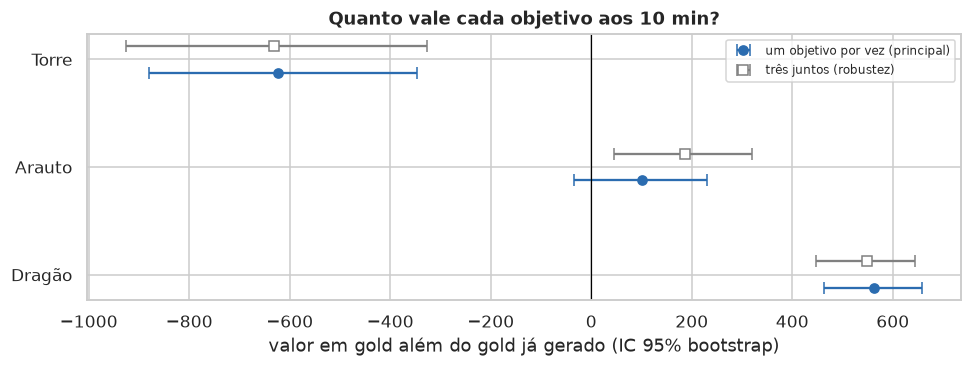

In [6]:
labels = {"dragons_diff": "Dragão", "heralds_diff": "Arauto", "towers_destroyed_diff": "Torre"}
fig, ax = plt.subplots(figsize=(9, 3.5))
y = np.arange(len(objectives))
series = [
    (separate, "o", "um objetivo por vez (principal)"),
    (joint, "s", "três juntos (robustez)"),
]
for offset, (frame, style, label) in enumerate(series):
    ax.errorbar(
        frame["gold_value"],
        y + (offset * 0.25 - 0.125),
        xerr=[frame["gold_value"] - frame["ci_low"], frame["ci_high"] - frame["gold_value"]],
        fmt=style,
        capsize=4,
        color=TEAM_PALETTE["blue"] if offset == 0 else "grey",
        markerfacecolor="white" if offset else TEAM_PALETTE["blue"],
        label=label,
    )
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y, [labels[o] for o in objectives])
ax.set(
    xlabel="valor em gold além do gold já gerado (IC 95% bootstrap)",
    title="Quanto vale cada objetivo aos 10 min?",
)
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
save_figure(fig, "hyp_objective_gold_value")
plt.show()

### Dragão e arauto

- **Dragão ≈ +560 de gold** (IC ~460–660): mesmo com o gold fixo, o time que tem o dragão vence
  mais. Faz sentido: o dragão não dá gold direto, então o valor dele quase não aparece no
  `gold_diff`. O buff permanente e o controle de rio aparecem aqui.
- **Arauto ≈ +100 de gold**, IC cruzando o zero no modelo principal. No modelo conjunto sobe
  para ~+190 (IC ~+45 a +320), porque arauto e torre andam juntos (o arauto é usado para
  derrubar torre) e o valor negativo da torre "devolve" parte do efeito ao arauto. A conclusão é
  que o valor do arauto além do gold é **fraco e sensível à especificação do modelo**.: **sem evidência** de valor além do gold.
  Também faz sentido: o valor do arauto é **converter** em torre e plates, e esse gold já está
  no `gold_diff`.

### O paradoxo da torre

**Torre ≈ −600 de gold.** Com o mesmo gold diff, o time que derrubou torre vence **menos**.
Isso não significa que derrubar torre atrapalhe. A pergunta é *de onde vem o gold*:

In [7]:
paradox = games.assign(
    gold_band=pd.cut(games[GOLD], [-np.inf, -2000, 0, 2000, 4000, np.inf]),
    torre=np.sign(games["towers_destroyed_diff"]).map(
        {-1: "vermelho tem mais", 0: "empate", 1: "azul tem mais"}
    ),
)
paradox_table = (
    paradox.groupby(["gold_band", "torre"], observed=True)
    .agg(
        n=(TARGET, "size"),
        xp_diff=("total_experience_diff", "mean"),
        kills_diff=("kills_diff", "mean"),
        win_rate=(TARGET, "mean"),
    )
    .round(2)
)
paradox_table

n     xp_diff  kills_diff  win_rate
gold_band        torre                                                    
(-inf, -2000.0]  azul tem mais         1      3.0000     -6.0000    0.0000
                 empate             1681 -2,408.3400     -5.4100    0.1400
                 vermelho tem mais   274 -2,721.5500     -5.3000    0.1200
(-2000.0, 0.0]   azul tem mais        28 -1,140.3200     -2.9600    0.2900
                 empate             2859   -700.6300     -1.5400    0.3700
                 vermelho tem mais    76   -178.8600      0.0300    0.3400
(0.0, 2000.0]    azul tem mais       105    160.3000     -0.1200    0.6000
                 empate             2840    616.2400      1.6200    0.6200
                 vermelho tem mais    23  1,096.4800      3.5200    0.8300
(2000.0, 4000.0] azul tem mais       140  1,608.2100      3.0500    0.7600
                 empate             1326  1,992.4600      4.7100    0.8600
                 vermelho tem mais     1  3,591.0000      7.0000    1.0000
(4000.0, inf]    azul tem mais       167  3,614.0800      7.5700    0.9400
                 empate              358  3,475.3000      8.0800    0.9400

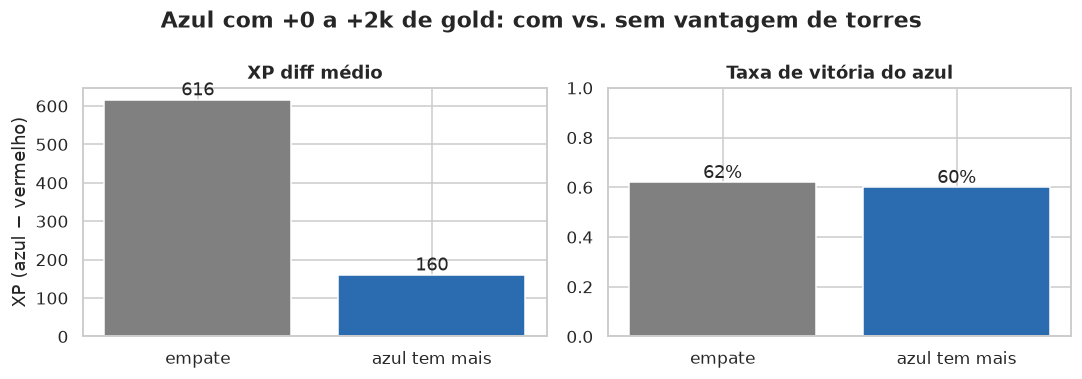

In [8]:
band = paradox[(paradox[GOLD] > 0) & (paradox[GOLD] <= 2000)]
summary = band.groupby("torre").agg(
    xp_diff=("total_experience_diff", "mean"), win_rate=(TARGET, "mean"), n=(TARGET, "size")
)
summary = summary.reindex(["empate", "azul tem mais"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
colors = ["grey", TEAM_PALETTE["blue"]]
axes[0].bar(summary.index, summary["xp_diff"], color=colors)
axes[0].set(title="XP diff médio", ylabel="XP (azul − vermelho)")
axes[1].bar(summary.index, summary["win_rate"], color=colors)
axes[1].set(title="Taxa de vitória do azul", ylim=(0, 1))
for ax, column, fmt in [(axes[0], "xp_diff", "{:.0f}"), (axes[1], "win_rate", "{:.0%}")]:
    for x, value in enumerate(summary[column]):
        ax.text(x, value, fmt.format(value), ha="center", va="bottom")
fig.suptitle("Azul com +0 a +2k de gold: com vs. sem vantagem de torres", fontweight="bold")
fig.tight_layout()
save_figure(fig, "hyp_tower_paradox")
plt.show()

In [9]:
control_sets = {
    "só gold": [],
    "gold + XP": ["total_experience_diff"],
    "gold + XP + kills": ["total_experience_diff", "kills_diff"],
}
sensitivity = pd.concat(
    {
        name: bootstrap_gold_equivalent(
            games, ["towers_destroyed_diff"], GOLD, controls=controls, n_boot=N_BOOT
        )
        for name, controls in control_sets.items()
    },
    names=["controles"],
).droplevel("objective")
sensitivity.round(0)

,gold_value,ci_low,ci_high,n_boot
controles,,,,
só gold,-624.0000,-881.0000,-347.0000,1000
gold + XP,-571.0000,-934.0000,-170.0000,1000
gold + XP + kills,-529.0000,-928.0000,-87.0000,1000


**Leitura:** na mesma faixa de gold, o time com torre tem **bem menos vantagem de XP**. A
vantagem dele veio de uma "injeção" de gold da estrutura, **sem a XP e as kills** que
acompanham uma vantagem construída em lutas e farm. Controlando por XP e kills, o valor da
torre sobe em direção a zero (−624 → −529), mas **continua negativo** (IC ≈ −930 a −90):
a explicação é **parcial**. O resíduo pode vir do que o dataset não tem, como composição (times
de dive e early game abrem torre cedo e escalam pior) ou gold concentrado num só jogador.

🎮 **Em linguagem de jogador:** *1.000 de gold vindos de torre valem menos que 1.000 de gold
vindos de kills e farm*, porque não vêm com nível. A torre não atrapalha: a chance bruta de quem
tem torre é 74% (EDA). O que acontece é que o `gold_diff` **superestima** a vantagem de quem
conseguiu o gold só com a torre.

**Implicação para o modelo:** é um argumento a favor de manter **gold, XP e torres juntos**
nas features. Em previsão, a colinearidade não atrapalha, e cada um carrega informação que o outro
não tem.

---
## H3 · First blood decide, ou só acompanha quem já está na frente?

- **H0 (bruta):** first blood e vitória são independentes · **Teste:** qui-quadrado, V de Cramér
- **H0 (ajustada):** β_first_blood = 0 dado `gold_diff` · **Teste:** Wald no logit · **Efeito:** odds ratio

In [10]:
fb = chi2_association(games, "blue_first_blood")
print(f"Qui-quadrado = {fb.chi2:.1f} · p = {fb.p_value:.1e} · V de Cramér = {fb.cramers_v:.3f}")
fb.contingency

Qui-quadrado = 402.2 · p = 1.8e-89 · V de Cramér = 0.202


blue_wins,0,1
blue_first_blood,,
0,2949,1943
1,2000,2987


In [11]:
confounding = raw_vs_adjusted_odds(
    games,
    [
        "blue_first_blood",
        "dragons_diff",
        "heralds_diff",
        "towers_destroyed_diff",
        "wards_placed_diff",
        "wards_destroyed_diff",
    ],
    controls=[GOLD],
    per=PER,
)
confounding[["per", "odds_ratio", "or_ci_low", "or_ci_high", "p_value"]]

per  odds_ratio  or_ci_low  or_ci_high  \
variable              model                                                 
blue_first_blood      bruto     1.0000      2.2668     2.0914      2.4569   
                      ajustado  1.0000      1.0082     0.9149      1.1109   
dragons_diff          bruto     1.0000      1.7269     1.6483      1.8092   
                      ajustado  1.0000      1.3731     1.3015      1.4486   
heralds_diff          bruto     1.0000      1.5206     1.4201      1.6283   
                      ajustado  1.0000      1.0612     0.9795      1.1497   
towers_destroyed_diff bruto     1.0000      3.1551     2.6991      3.6882   
                      ajustado  1.0000      0.6867     0.5735      0.8222   
wards_placed_diff     bruto    10.0000      1.0175     0.9999      1.0353   
                      ajustado 10.0000      1.0055     0.9853      1.0261   
wards_destroyed_diff  bruto    10.0000      1.7191     1.4887      1.9852   
                      ajustado 10.0000      1.0438     0.8864      1.2291   

                                p_value  
variable              model              
blue_first_blood      bruto      0.0000  
                      ajustado   0.8696  
dragons_diff          bruto      0.0000  
                      ajustado   0.0000  
heralds_diff          bruto      0.0000  
                      ajustado   0.1464  
towers_destroyed_diff bruto      0.0000  
                      ajustado   0.0000  
wards_placed_diff     bruto      0.0510  
                      ajustado   0.5962  
wards_destroyed_diff  bruto      0.0000  
                      ajustado   0.6076

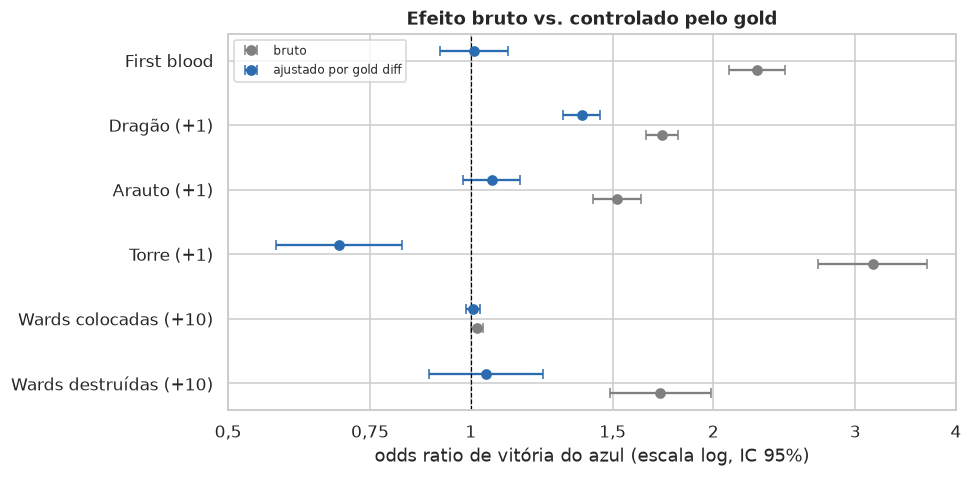

In [12]:
pretty = {
    "blue_first_blood": "First blood",
    "dragons_diff": "Dragão (+1)",
    "heralds_diff": "Arauto (+1)",
    "towers_destroyed_diff": "Torre (+1)",
    "wards_placed_diff": "Wards colocadas (+10)",
    "wards_destroyed_diff": "Wards destruídas (+10)",
}
fig, ax = plt.subplots(figsize=(9, 4.5))
variables = list(pretty)
y = np.arange(len(variables))
for offset, (model, color) in enumerate([("bruto", "grey"), ("ajustado", TEAM_PALETTE["blue"])]):
    rows = confounding.xs(model, level="model").loc[variables]
    ax.errorbar(
        rows["odds_ratio"],
        y + (0.15 if offset == 0 else -0.15),
        xerr=[rows["odds_ratio"] - rows["or_ci_low"], rows["or_ci_high"] - rows["odds_ratio"]],
        fmt="o",
        capsize=3,
        color=color,
        label="ajustado por gold diff" if model == "ajustado" else "bruto",
    )
ax.axvline(1, color="black", linestyle="--", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlim(0.5, 4)
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 4], ["0,5", "0,75", "1", "1,5", "2", "3", "4"])
ax.minorticks_off()
ax.set_yticks(y, [pretty[v] for v in variables])
ax.invert_yaxis()
ax.set(
    xlabel="odds ratio de vitória do azul (escala log, IC 95%)",
    title="Efeito bruto vs. controlado pelo gold",
)
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "hyp_raw_vs_adjusted_odds")
plt.show()

**Conclusão:** brutos, first blood e vitória estão claramente associados (OR ≈ 2,3, p ≈ 1e-89).
Controlando pelo gold, o OR **cai para ≈ 1,0** (IC ~0,91–1,11). O efeito some por completo.

Isso é **confusão** em estado puro: o first blood vale ~400 de gold (kill + bônus), e quem
o consegue costuma já estar jogando melhor. Depois que o `gold_diff` entra, o first blood não
acrescenta nada.

🎮 **Em linguagem de jogador:** *o first blood não decide o jogo; ele só entra na conta do
gold.* Perder o first blood e empatar o gold até os 10 min equivale a não ter perdido nada.

**Implicação para o modelo:** `blue_first_blood` deve ter importância perto de zero num modelo
que já tem gold. É candidata a sair, decisão a confirmar por CV na Etapa 5.

---
## H4 · Visão importa no early?

Mesmo desenho da H3, com `wards_placed_diff` (cap no p99) e `wards_destroyed_diff`, lidos por
**+10 wards**.

- **H0:** β_wards = 0 dado `gold_diff` · **Teste:** Wald · **Efeito:** odds ratio por +10 wards

In [13]:
or_columns = ["per", "odds_ratio", "or_ci_low", "or_ci_high", "p_value"]
confounding.loc[["wards_placed_diff", "wards_destroyed_diff"], or_columns]

per  odds_ratio  or_ci_low  or_ci_high  \
variable             model                                                 
wards_placed_diff    bruto    10.0000      1.0175     0.9999      1.0353   
                     ajustado 10.0000      1.0055     0.9853      1.0261   
wards_destroyed_diff bruto    10.0000      1.7191     1.4887      1.9852   
                     ajustado 10.0000      1.0438     0.8864      1.2291   

                               p_value  
variable             model              
wards_placed_diff    bruto      0.0510  
                     ajustado   0.5962  
wards_destroyed_diff bruto      0.0000  
                     ajustado   0.6076

**Conclusão:**
- **Wards colocadas:** nem o efeito bruto é claro (OR ≈ 1,02 por +10, p ≈ 0,05). Controlando
  pelo gold, nada (OR ≈ 1,01, p ≈ 0,6).
- **Wards destruídas:** associação bruta forte (OR ≈ 1,7 por +10). Some quando o gold entra
  (OR ≈ 1,04, IC cruzando 1). Quem limpa visão é quem já domina o mapa, e esse domínio já
  aparece em gold.

🎮 **Em linguagem de jogador:** *aos 10 minutos, a quantidade de wards não muda o jogo de um
jeito que apareça no resultado.* Ressalva importante: o dataset conta **quantas** wards, não
**onde**. Uma ward bem colocada antes do dragão provavelmente vale muito, mas o efeito dela
aparece no dragão e no gold, não na contagem.

---
## Resumo · correção para múltiplos testes (Holm)

São 7 testes principais. Com α = 0,05 em cada um, a chance de pelo menos um falso positivo
passa de 30%. A correção de **Holm** ajusta os p-valores controlando essa taxa (FWER).

In [14]:
adjusted = confounding.xs("ajustado", level="model")
or_tests = ["blue_first_blood", "wards_placed_diff", "wards_destroyed_diff"]


def fmt_gold(o: str) -> str:
    row = gold_values.loc[o]
    return f"{row['gold_value']:+.0f} gold [{row['ci_low']:+.0f}, {row['ci_high']:+.0f}]"


def fmt_or(v: str) -> str:
    row = adjusted.loc[v]
    return f"OR {row['odds_ratio']:.2f} [{row['or_ci_low']:.2f}, {row['or_ci_high']:.2f}]"


tests = pd.DataFrame(
    {
        "hipótese": [
            "H1 · vantagem do lado azul",
            "H2 · dragão (dado gold)",
            "H2 · arauto (dado gold)",
            "H2 · torre (dado gold)",
            "H3 · first blood (dado gold)",
            "H4 · wards colocadas (dado gold)",
            "H4 · wards destruídas (dado gold)",
        ],
        "efeito": [
            f"taxa {side.rate:.1%} (h = {side.cohens_h:+.3f})",
            *(fmt_gold(o) for o in objectives),
            *(fmt_or(v) for v in or_tests),
        ],
        "p": [side.p_value, *gold_values["p_value"], *adjusted.loc[or_tests, "p_value"]],
    }
)
reject, p_holm, _, _ = multipletests(tests["p"], alpha=0.05, method="holm")
tests = tests.assign(p_holm=p_holm, significativo=np.where(reject, "sim", "não"))
tests.style.format({"p": "{:.2e}", "p_holm": "{:.2e}"}).hide(axis="index")

hipótese,efeito,p,p_holm,significativo
H1 · vantagem do lado azul,taxa 49.9% (h = -0.002),8.56e-01,1.00e+00,não
H2 · dragão (dado gold),"+563 gold [+464, +657]",3.64e-31,2.55e-30,sim
H2 · arauto (dado gold),"+102 gold [-34, +231]",1.46e-01,7.32e-01,não
H2 · torre (dado gold),"-624 gold [-881, -347]",4.31e-05,2.58e-04,sim
H3 · first blood (dado gold),"OR 1.01 [0.91, 1.11]",8.70e-01,1.00e+00,não
H4 · wards colocadas (dado gold),"OR 1.01 [0.99, 1.03]",5.96e-01,1.00e+00,não
H4 · wards destruídas (dado gold),"OR 1.04 [0.89, 1.23]",6.08e-01,1.00e+00,não


## O que levamos para o modelo

| Achado | Implicação |
|---|---|
| Lado sozinho não carrega informação mensurável | Nenhuma feature de lado; o intercepto do modelo absorve qualquer resíduo |
| **Dragão vale ~560 de gold além do gold** | `dragons_diff` é informação nova: manter |
| Arauto não vale nada além do gold que gera | `heralds_diff` deve ter peso baixo; manter e deixar a CV decidir |
| Gold de torre vale menos que gold de luta e farm | Manter **gold e XP** juntos (o XP corrige o gold "inflado" pela torre) |
| First blood e wards: efeito some com o gold | Candidatas a remoção, testadas na Etapa 5 (com/sem) |
| Tudo converge para o **gold diff** | Confirma o benchmark: gold sozinho ≈ 0,80 de AUC; o resto adiciona pouco, e o teto ≈ 0,82 é realista |

**Frase para o stakeholder:** *"Aos 10 minutos, quase tudo o que importa já virou gold. As
exceções são o dragão, que vale cerca de 560 de gold a mais do que mostra o placar, e a
origem do gold: vantagem de torre sem nível vale menos do que parece."*